# NYC Flights — Exploratory Data Analysis

**Dataset:** `nycflights13::flights` · **Period:** 2013  
**Author:** Miguel Martín González

---

This notebook explores flight volume and departure/arrival delays across time, origin airports, airlines, and destinations. The analysis focuses on descriptive patterns in the available flight records.

## Notebook guide

1. **Setup and data overview** — packages, structure, missing values
2. **Temporal patterns** — extreme delays, monthly summaries, scheduled time, weekdays, and days of the month
3. **Airports, airlines, and destinations** — flight volume and delay comparisons
4. **Summary and limitations** — key observations and interpretation cautions


## 1. Setup and data overview

Load the packages and inspect the dataset's structure before starting the analysis.

In [123]:
#install.packages('nycflights13') ## If not already installed
library(nycflights13)
library(dplyr)
library(ggplot2)
library(lubridate)

In [124]:
 data('flights')
 head(flights , 5)
 dim(flights)


year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
2013,1,1,517,515,2,830,819,11,UA,1545,N14228,EWR,IAH,227,1400,5,15,2013-01-01 05:00:00
2013,1,1,533,529,4,850,830,20,UA,1714,N24211,LGA,IAH,227,1416,5,29,2013-01-01 05:00:00
2013,1,1,542,540,2,923,850,33,AA,1141,N619AA,JFK,MIA,160,1089,5,40,2013-01-01 05:00:00
2013,1,1,544,545,-1,1004,1022,-18,B6,725,N804JB,JFK,BQN,183,1576,5,45,2013-01-01 05:00:00
2013,1,1,554,600,-6,812,837,-25,DL,461,N668DN,LGA,ATL,116,762,6,0,2013-01-01 06:00:00


[1] 336776     19

### Variables of interest

The most relevant variables depend on the question being investigated. To study temporal patterns in flight volume and delays, this notebook focuses on **month, day, hour, and scheduled departure time**, and later compares patterns across airports, carriers, and destinations.

In [125]:
 summary(flights)

      year          month             day           dep_time    sched_dep_time
 Min.   :2013   Min.   : 1.000   Min.   : 1.00   Min.   :   1   Min.   : 106  
 1st Qu.:2013   1st Qu.: 4.000   1st Qu.: 8.00   1st Qu.: 907   1st Qu.: 906  
 Median :2013   Median : 7.000   Median :16.00   Median :1401   Median :1359  
 Mean   :2013   Mean   : 6.549   Mean   :15.71   Mean   :1349   Mean   :1344  
 3rd Qu.:2013   3rd Qu.:10.000   3rd Qu.:23.00   3rd Qu.:1744   3rd Qu.:1729  
 Max.   :2013   Max.   :12.000   Max.   :31.00   Max.   :2400   Max.   :2359  
                                                 NAs    :8255                 
   dep_delay          arr_time    sched_arr_time   arr_delay       
 Min.   : -43.00   Min.   :   1   Min.   :   1   Min.   : -86.000  
 1st Qu.:  -5.00   1st Qu.:1104   1st Qu.:1124   1st Qu.: -17.000  
 Median :  -2.00   Median :1535   Median :1556   Median :  -5.000  
 Mean   :  12.64   Mean   :1502   Mean   :1536   Mean   :   6.895  
 3rd Qu.:  11.00   3rd Qu.:1

In [126]:
sum(!complete.cases(flights))


[1] 9430

### Missing values and data preparation

The initial inspection reports **8,255 missing values in `dep_delay`**, **9,430 in `arr_delay`**, and **9,430 in `air_time`**. There are **9,430 rows with at least one missing value**. Rows missing `dep_delay` are therefore a subset of rows missing at least one of the other listed variables.

Missing values may reflect data issues or flights that did not operate as planned. The following cell separates incomplete records into `cancelled` and retains complete cases in `flights` for the subsequent analysis. This is a simplifying choice: missing records may warrant a separate investigation, especially when studying cancellations.

In [127]:
cancelled = flights[ !complete.cases(flights) , ]
flights = flights[ complete.cases(flights), ] 
#head(cancelled)
#head(flights)
#sum(!complete.cases(flights))

In [128]:
flights = flights %>% arrange(dep_delay) #arranging flights by departure delay order
#head(flights, 10)

## 2. Temporal patterns in flight delays

### Flights with the largest departure delays

Inspect the records at the end of the departure-delay-sorted data to identify the most extreme departure delays.

In [129]:
tail(flights)

year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
2013,4,10,1100,1900,960,1342,2211,931,DL,2391,N959DL,JFK,TPA,139,1005,19,0,2013-04-10 19:00:00
2013,7,22,845,1600,1005,1044,1815,989,MQ,3075,N665MQ,JFK,CVG,96,589,16,0,2013-07-22 16:00:00
2013,9,20,1139,1845,1014,1457,2210,1007,AA,177,N338AA,JFK,SFO,354,2586,18,45,2013-09-20 18:00:00
2013,1,10,1121,1635,1126,1239,1810,1109,MQ,3695,N517MQ,EWR,ORD,111,719,16,35,2013-01-10 16:00:00
2013,6,15,1432,1935,1137,1607,2120,1127,MQ,3535,N504MQ,JFK,CMH,74,483,19,35,2013-06-15 19:00:00
2013,1,9,641,900,1301,1242,1530,1272,HA,51,N384HA,JFK,HNL,640,4983,9,0,2013-01-09 09:00:00


### Flights with the largest arrival delays

Inspect the records with the largest arrival delays and compare them with the departure-delay extremes.

In [130]:
tail(flights %>% arrange(arr_delay))

year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>
2013,4,10,1100,1900,960,1342,2211,931,DL,2391,N959DL,JFK,TPA,139,1005,19,0,2013-04-10 19:00:00
2013,7,22,845,1600,1005,1044,1815,989,MQ,3075,N665MQ,JFK,CVG,96,589,16,0,2013-07-22 16:00:00
2013,9,20,1139,1845,1014,1457,2210,1007,AA,177,N338AA,JFK,SFO,354,2586,18,45,2013-09-20 18:00:00
2013,1,10,1121,1635,1126,1239,1810,1109,MQ,3695,N517MQ,EWR,ORD,111,719,16,35,2013-01-10 16:00:00
2013,6,15,1432,1935,1137,1607,2120,1127,MQ,3535,N504MQ,JFK,CMH,74,483,19,35,2013-06-15 19:00:00
2013,1,9,641,900,1301,1242,1530,1272,HA,51,N384HA,JFK,HNL,640,4983,9,0,2013-01-09 09:00:00


**Initial observation.** Flights with very large arrival delays also tend to have large departure delays. This suggests that departure delays may carry through to arrival, although this descriptive comparison does not establish causality.

### Monthly departure delays

For flights with a departure delay greater than 10 minutes, calculate the number of flights and two measures of central tendency for each month: the mean and median departure delay.

In [141]:
monthly_delays <- flights %>% filter(dep_delay>10) %>%
 group_by(month) %>%
    summarise(
    number_of_flights = n(),
    mean_departure_delay = mean(dep_delay),
    median_departure_delay = median(dep_delay)
  ) %>%
  arrange(month)

monthly_delays

month,number_of_flights,mean_departure_delay,median_departure_delay
<int>,<int>,<dbl>,<dbl>
1,5865,54.86581,36
2,5686,53.57035,35
3,7255,58.34418,38
4,7119,62.70656,42
5,7442,56.65332,38
6,8790,68.93242,45
7,9497,68.30199,45
8,7435,55.82461,36
9,4528,57.60402,33


### Scheduled departure time and departure delay

Explore the relationship between scheduled departure time and departure delay across the retained flight records.

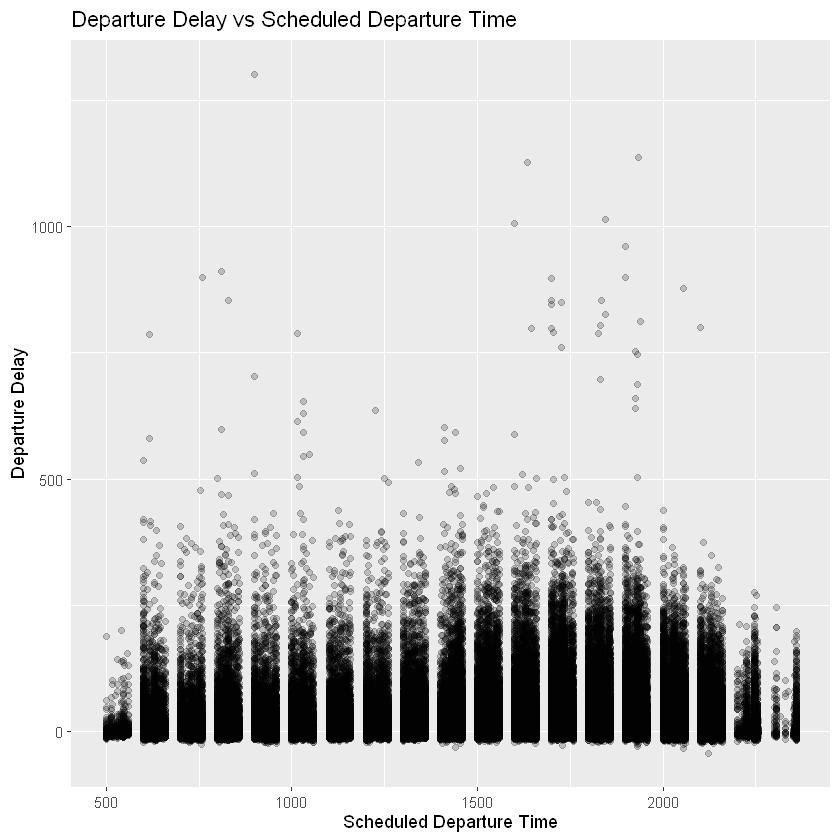

In [132]:
flights %>%
  ggplot(aes(x = sched_dep_time, y = dep_delay)) +
  geom_point(alpha = 0.2) +
  labs(
    title = "Departure Delay vs Scheduled Departure Time",
    x = "Scheduled Departure Time",
    y = "Departure Delay"
  )

In [133]:
hour_delays <- flights %>%
 group_by(hour) %>%
    summarise(
    number_of_flights = n(),
    mean_departure_delay = mean(dep_delay),
    median_departure_delay = median(dep_delay)
  ) %>%
  arrange(hour)

hour_delays

hour,number_of_flights,mean_departure_delay,median_departure_delay
<dbl>,<int>,<dbl>,<dbl>
5,1940,0.6886598,-3
6,25447,1.5950014,-3
7,22475,1.9103448,-3
8,26734,4.1067554,-3
9,19931,4.5397622,-3
10,16370,6.4489921,-3
11,15689,7.1477468,-3
12,17744,8.5193305,-2
13,19457,11.3238937,-1


### Scheduled departure time for flights delayed by more than 10 minutes

Focus on flights with `dep_delay > 10` to examine whether the timing pattern differs for more substantially delayed departures.

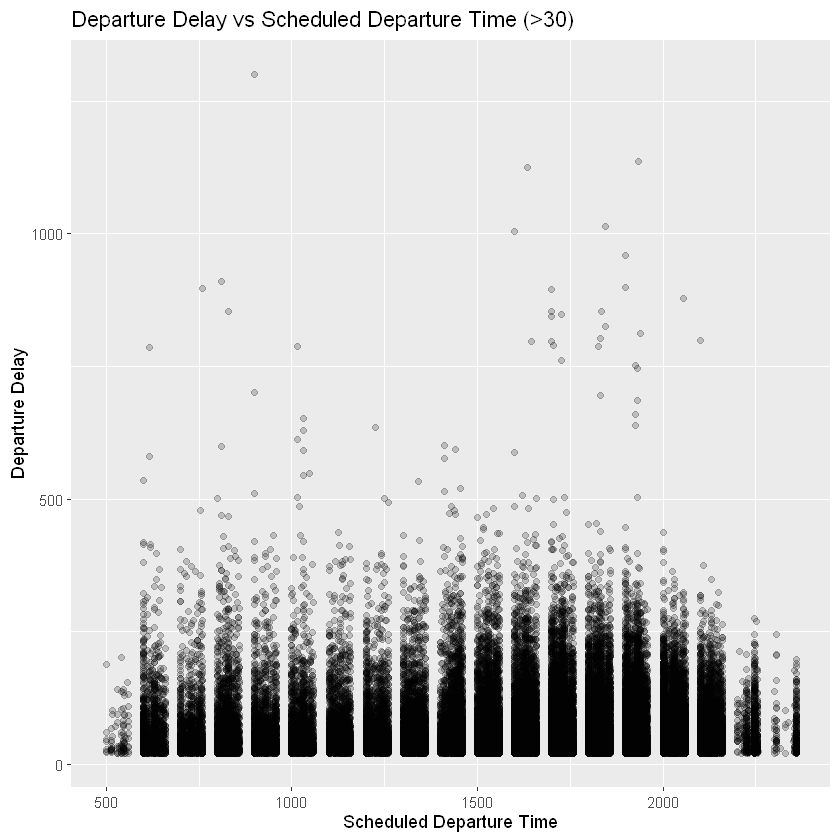

In [134]:
flights %>% filter(dep_delay >20) %>%
  ggplot(aes(x = sched_dep_time, y = dep_delay)) +
  geom_point(alpha = 0.2) +
  labs(
    title = "Departure Delay vs Scheduled Departure Time (>30)",
    x = "Scheduled Departure Time",
    y = "Departure Delay"
  )

In [135]:
hour_delays <- flights %>% filter(dep_delay>20) %>%
 group_by(hour) %>%
    summarise(
    number_of_flights = n(),
    mean_departure_delay = mean(dep_delay),
    median_departure_delay = median(dep_delay)
  ) %>%
  arrange(hour)

hour_delays

hour,number_of_flights,mean_departure_delay,median_departure_delay
<dbl>,<int>,<dbl>,<dbl>
5,88,56.85227,39
6,1557,67.19717,45
7,1474,64.68657,43
8,2505,67.98683,45
9,1982,67.72704,46
10,1942,71.36663,50
11,2063,67.58265,46
12,2727,64.73451,46
13,3537,66.27566,47


**Interpretation.** The hourly summaries and plots suggest that delays are more common later in the day, with notable activity from the afternoon into the evening. Flight volume and congestion may contribute to this pattern, and delays from earlier flights may accumulate over the course of the day. These are possible explanations rather than causal conclusions.

In [136]:
flights = flights %>%
  mutate(
    weekday = wday(
      make_date(year, month, day),
      label = TRUE,
      abbr = FALSE
    )
  )

### Delays by day of the week

For flights delayed by more than 10 minutes, summarize the flight count, mean delay, and median delay for each weekday.

In [142]:
wday_delays = flights %>% filter(dep_delay > 10) %>%
 group_by(weekday) %>%
    summarise(
    number_of_flights = n(),
    mean_departure_delay = mean(dep_delay),
    median_departure_delay = median(dep_delay)
  ) %>%
  arrange(weekday)

wday_delays

weekday,number_of_flights,mean_departure_delay,median_departure_delay
<ord>,<int>,<dbl>,<dbl>
Sunday,10958,56.53605,35
Monday,13117,63.05733,41
Tuesday,11491,55.59751,37
Wednesday,11581,58.65677,37
Thursday,13949,62.03305,41
Friday,13568,58.92261,39
Saturday,7637,49.05801,31


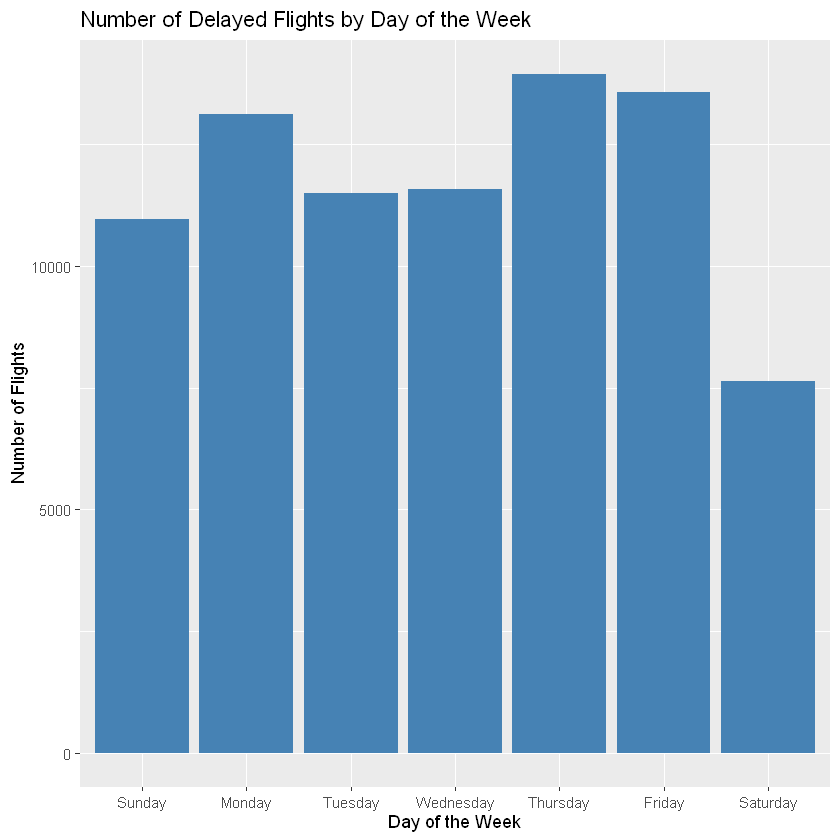

In [156]:
ggplot(wday_delays, aes(x = weekday, y = number_of_flights)) +
  geom_col(fill = "steelblue") +
  labs(
    title = "Number of Delayed Flights by Day of the Week",
    x = "Day of the Week",
    y = "Number of Flights"
  )

### Delays by day of the month

Compare the number of flights delayed by more than 10 minutes across day numbers 1–31. Because this groups together the same day number across months, it is not a calendar-date time series.

In [164]:
mday_delays = flights %>% filter(dep_delay > 10) %>%
 group_by(day) %>%
    summarise(
    number_of_flights = n(),
    mean_departure_delay = mean(dep_delay),
    median_departure_delay = median(dep_delay)
  ) %>%
  arrange(day)

mday_delays

day,number_of_flights,mean_departure_delay,median_departure_delay
<int>,<int>,<dbl>,<dbl>
1,2859,61.52011,42
2,2690,63.54572,39
3,2629,54.25827,35
4,1949,46.72755,31
5,1895,59.34406,34
6,2120,47.83538,31
7,2740,63.04270,40
8,3214,75.30180,52
9,2926,57.75871,40


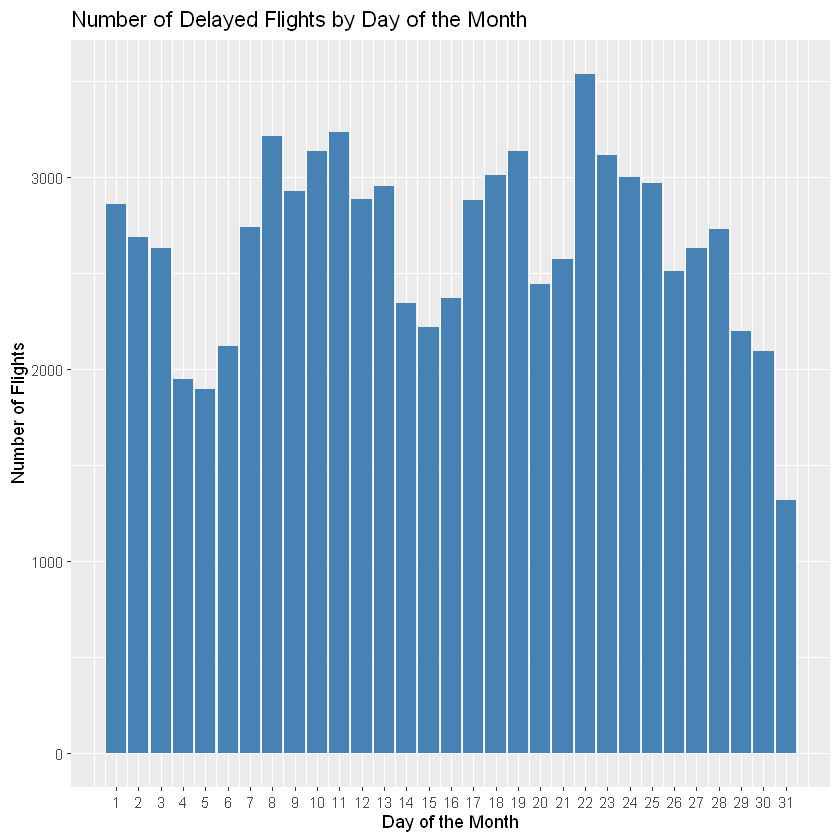

In [165]:
ggplot(mday_delays, aes(x = day, y = number_of_flights)) +
  geom_col(fill = "steelblue") +
  scale_x_continuous(breaks = 1:31) +
  labs(
    title = "Number of Delayed Flights by Day of the Month",
    x = "Day of the Month",
    y = "Number of Flights"
  )

**Interpretation.** The count of flights delayed by more than 10 minutes appears lower on Saturdays and higher on some weekdays, including Thursday, Friday, and Monday. Differences in flight volume and travel demand may contribute. Day-of-month patterns need not match weekday patterns because they aggregate different calendar dates and seasonal conditions.

## 3. Comparisons across airports, airlines, and destinations

### Monthly flight volume by origin airport

Compare the number of flight records by month for each origin airport.

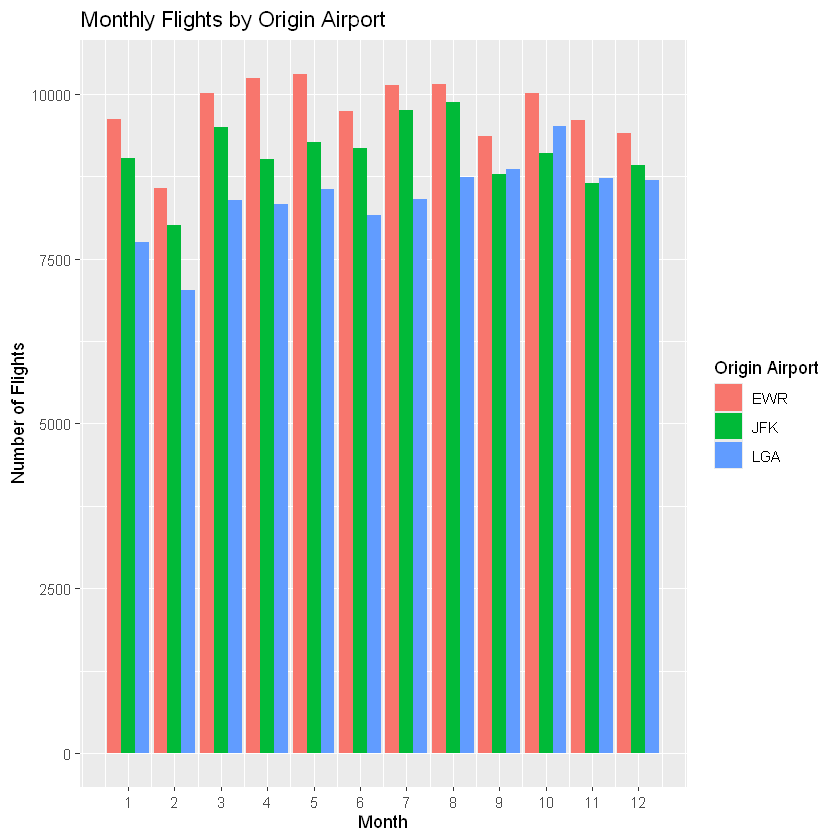

In [172]:
monthly_flights <- flights %>%
  group_by(month, origin) %>%
  summarise(
    number_of_flights = n(),
    .groups = "drop_last"
  )

ggplot(monthly_flights, aes(x = month, y = number_of_flights, fill = origin)) +
  geom_col(position = "dodge") +
  scale_x_continuous(breaks = 1:12) +
  labs(
    title = "Monthly Flights by Origin Airport",
    x = "Month",
    y = "Number of Flights",
    fill = "Origin Airport"
  )

### Monthly flights delayed by more than 10 minutes, by origin

Compare monthly counts of departures delayed by more than 10 minutes across origin airports.

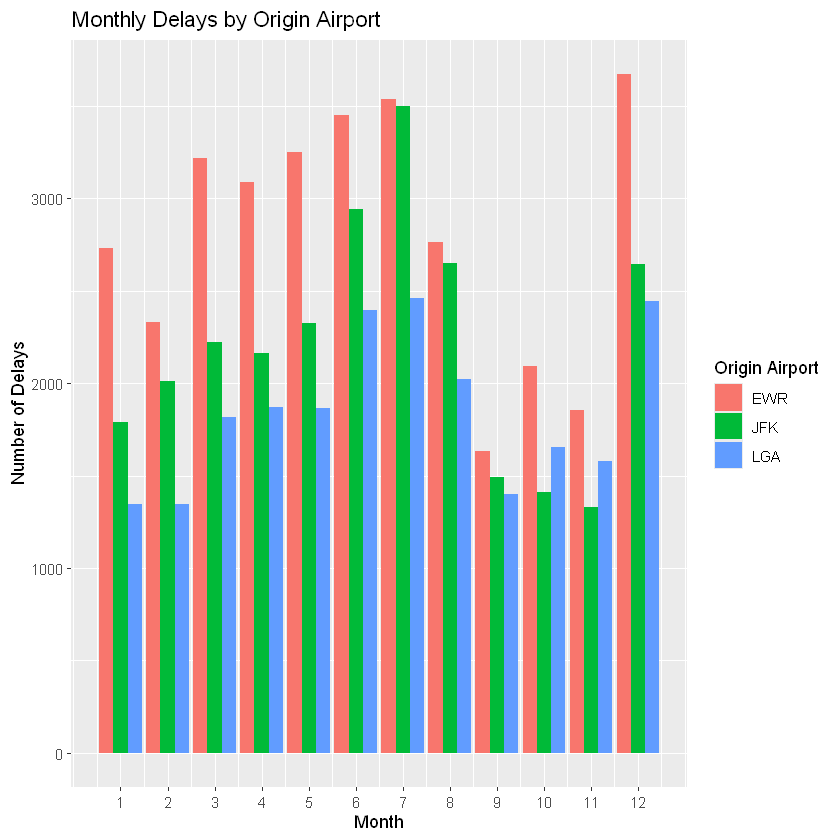

In [173]:
monthly_delays <- flights %>% filter(dep_delay > 10) %>%
  group_by(month, origin) %>%
  summarise(
    number_of_flights = n(),
    .groups = "drop_last"
  )

ggplot(monthly_delays, aes(x = month, y = number_of_flights, fill = origin)) +
  geom_col(position = "dodge") +
  scale_x_continuous(breaks = 1:12) +
  labs(
    title = "Monthly Delays by Origin Airport",
    x = "Month",
    y = "Number of Delays",
    fill = "Origin Airport"
  )

### Flight volume by carrier

Summarize total flights and delay metrics for each carrier, then compare carrier flight volumes and the number of flights delayed by more than 10 minutes.

In [216]:
carrier_stats <- flights %>%
  group_by(carrier) %>%
  summarise(
    number_of_flights = n(),
    delayed_flights = sum(dep_delay > 10),
    delay_ratio = delayed_flights / number_of_flights,
    mean_dep_delay = mean(dep_delay),
    mean_arr_delay = mean(arr_delay),
    .groups = "drop"
  ) %>%
  arrange(desc(number_of_flights))

carrier_delays <- flights %>% filter(dep_delay>10) %>%
  group_by(carrier) %>%
  summarise(
    number_of_flights = n(),
    mean_dep_delay = mean(dep_delay),
    mean_arr_delay = mean(arr_delay),
    .groups = "drop"
  ) %>%
  arrange(desc(number_of_flights))


carrier_stats
#carrier_delays


carrier,number_of_flights,delayed_flights,delay_ratio,mean_dep_delay,mean_arr_delay
<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>
UA,57782,14775,0.25570247,12.016908,3.5580111
B6,54049,14399,0.26640641,12.967548,9.4579733
EV,51108,17388,0.34022071,19.838929,15.7964311
DL,47658,9307,0.19528726,9.223950,1.6443409
AA,31947,5974,0.18699721,8.569130,0.3642909
MQ,25037,6030,0.24084355,10.445381,10.7747334
US,19831,2912,0.14684080,3.744693,2.1295951
9E,17294,4997,0.28894414,16.439574,7.3796692
WN,12044,3875,0.32173696,17.661657,9.6491199


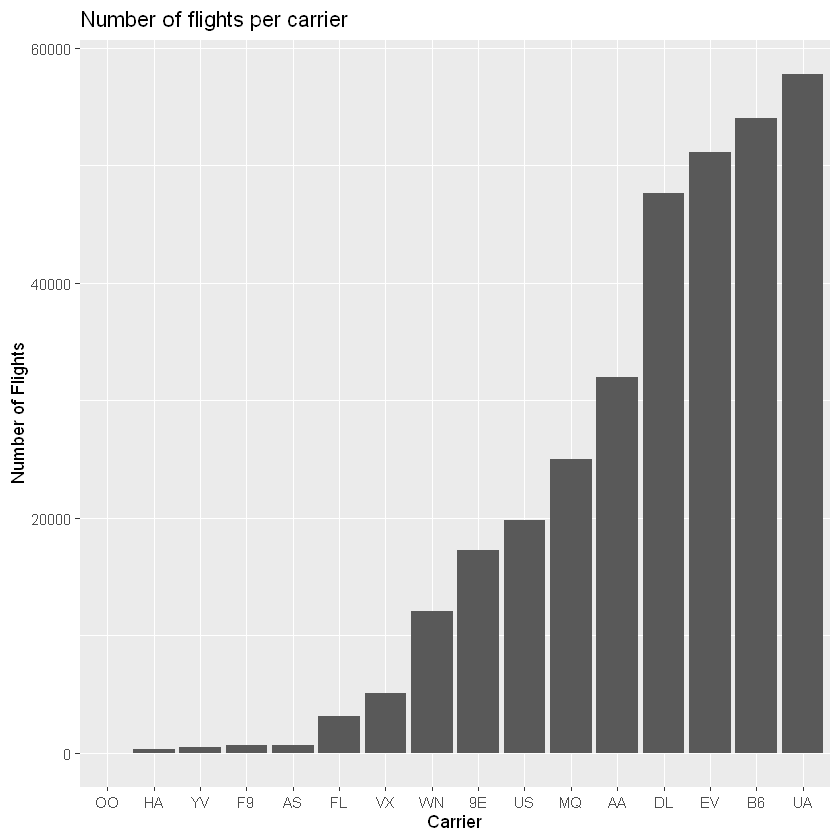

In [ ]:
ggplot(carrier_stats , aes(x = reorder(carrier, number_of_flights), y = number_of_flights)) +
  geom_col() +
  labs(
    title = "Number of flights per carrier",
    x = "Carrier",
    y = "Number of Flights",
  )

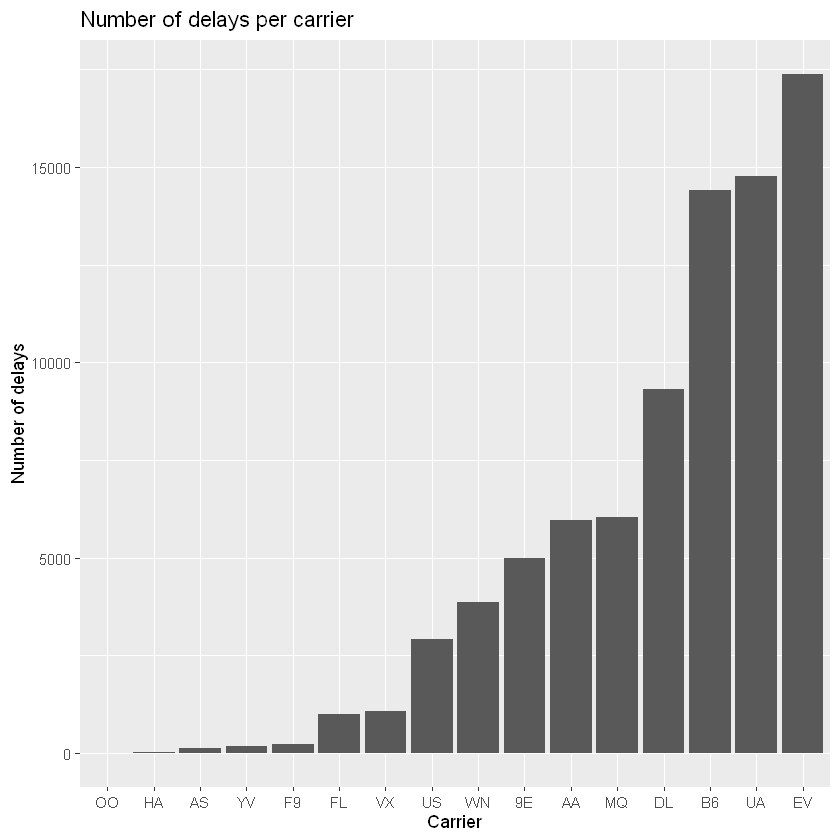

In [198]:
ggplot(carrier_delays , aes(x = reorder(carrier, number_of_flights), y = number_of_flights)) +
  geom_col() +
  labs(
    title = "Number of delays per carrier",
    x = "Carrier",
    y = "Number of delays",
  )

### Flight volume and delays by destination

Summarize flight volume and delay measures for each destination. The table below applies a threshold to focus the displayed results on destinations with more than 2,500 delayed flights.

In [212]:
destination_stats <- flights %>%
  group_by(dest) %>%
  summarise(
    number_of_flights = n(),
    number_of_delays = sum(dep_delay > 10),
    delay_ratio = number_of_delays / number_of_flights ,
    mean_dep_delay = mean(dep_delay),
    mean_arr_delay = mean(arr_delay),
    .groups = "drop"
  ) %>%
  arrange(desc(number_of_flights)) %>%
  filter(number_of_delays > 2500)


destination_delays <- flights %>% filter(dep_delay>10) %>%
  group_by(dest) %>%
  summarise(
    number_of_flights = n(),
    mean_dep_delay = mean(dep_delay),
    mean_arr_delay = mean(arr_delay),
    .groups = "drop"
  ) %>%
  arrange(desc(number_of_flights)) %>% filter(number_of_flights > 2500)


destination_stats
#destination_delays

dest,number_of_flights,number_of_delays,delay_ratio,mean_dep_delay,mean_arr_delay
<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>
ATL,16837,3873,0.2300291,12.425135,11.3001128
ORD,16566,4209,0.2540746,13.432814,5.8766148
LAX,16026,3390,0.2115313,9.351242,0.5471109
BOS,15022,3145,0.2093596,8.662029,2.9143922
MCO,13967,3305,0.2366292,11.265340,5.4546431
CLT,13674,2792,0.2041831,9.196431,7.3603189
SFO,13173,3213,0.2439080,12.738708,2.6728915
FLL,11897,3145,0.2643524,12.683786,8.0821215


### Destinations with the highest counts of delayed flights

Visualize destinations with the highest counts of flights delayed by more than 10 minutes, based on the filtered destination table.

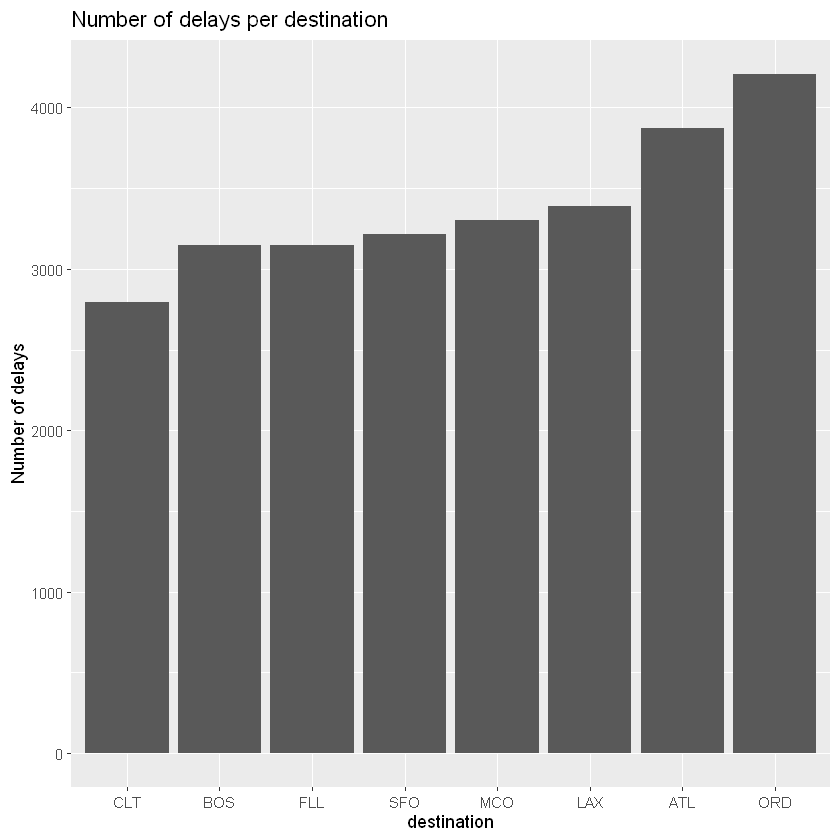

In [222]:
ggplot(destination_delays , aes(x = reorder(dest, number_of_flights), y = number_of_flights)) +
  geom_col() +
  labs(
    title = "Number of delays per destination",
    x = "destination",
    y = "Number of delays",
  ) #+
  #theme(
  #  axis.text.x = element_blank()
  #)

### Delay ratios among higher-volume carriers and destinations

Compare delay ratios for carriers with more than 15,000 flights and destinations with more than 5,000 flights. These thresholds focus the comparison on higher-volume groups.

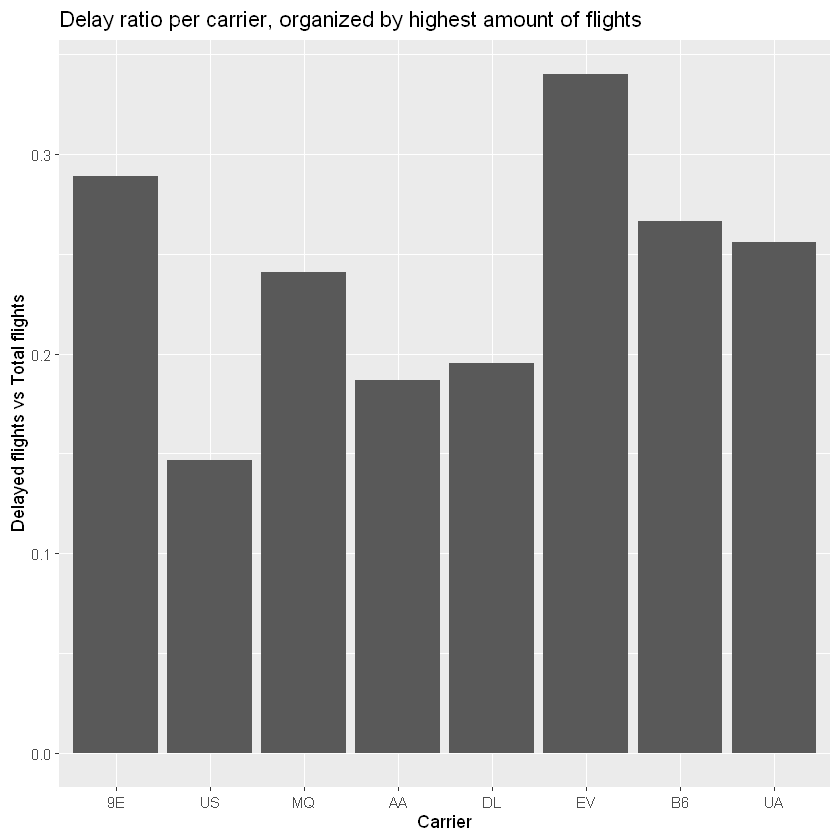

In [220]:
ggplot(carrier_stats %>% filter(number_of_flights > 15000) , aes(x = reorder(carrier, number_of_flights), y = delay_ratio)) +
  geom_col() +
  labs(
    title = "Delay ratio per carrier, organized by highest amount of flights",
    x = "Carrier",
    y = "Delayed flights vs Total flights",
  )

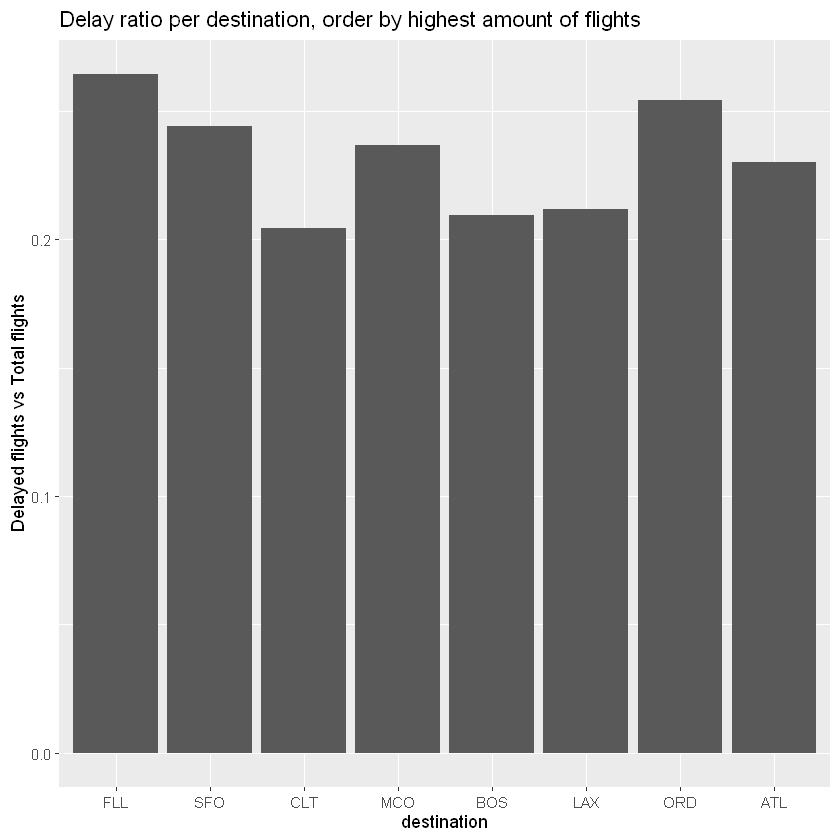

In [224]:
ggplot(destination_stats %>% filter(number_of_flights > 5000) , aes(x = reorder(dest, number_of_flights), y = delay_ratio)) +
  geom_col() +
  labs(
    title = "Delay ratio per destination, order by highest amount of flights",
    x = "destination",
    y = "Delayed flights vs Total flights",
  )

## 4. Summary and limitations

The analysis compares groups with different levels of flight volume, so the final ratio comparisons focus on higher-volume carriers and destinations. This reduces—but does not eliminate—the influence of small sample sizes and seasonal variation.

The original analysis reports that flight volume does not always correspond to a higher ratio of delays. It identifies `9E` and `EV` among carriers with relatively high proportions of departures delayed by more than 10 minutes, and `FLL` and `ORD` among destinations with relatively high delay ratios. These observations should be interpreted in light of the selected thresholds, the handling of missing records, and the fact that the analysis is descriptive rather than causal.

---

*End of notebook.*